# TA-07: Implementasi Q-Learning untuk Skenario RL Diskrit
**Skenario:** Kurir Pengantar Paket di Grid Kampus 5x5 (lanjutan TP-07)  
NIM 301240033 - Pembelajaran Mesin, Teknik Informatika UNIBBA

## 1. Persiapan Environment
Environment dibuat dengan kelas Python murni (tanpa Gymnasium). State = (baris, kolom, status paket) -> 50 state, 4 aksi.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt, pandas as pd

# ===== 1. ENVIRONMENT =====
class KurirEnv:
    """Grid 5x5. State = (baris, kolom, bawa_paket) -> id 0..49. Aksi: 0=Atas,1=Bawah,2=Kiri,3=Kanan"""
    N = 5
    START, PICKUP, DEST = (0, 0), (0, 4), (4, 0)
    MACET = {(0, 2), (2, 2), (3, 1)}
    MOVES = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}
    n_states, n_actions = 50, 4

    def encode(self, r, c, p): return (r * self.N + c) * 2 + p
    def decode(self, s): p = s % 2; rc = s // 2; return rc // self.N, rc % self.N, p
    def reset(self):
        self.r, self.c = self.START; self.p = 0
        return self.encode(self.r, self.c, self.p)
    def step(self, a):
        return self.transition(self.encode(self.r, self.c, self.p), a, commit=True)
    def transition(self, s, a, commit=False):
        r, c, p = self.decode(s)
        dr, dc = self.MOVES[a]; nr, nc = r + dr, c + dc
        done = False
        if not (0 <= nr < self.N and 0 <= nc < self.N):
            nr, nc, reward = r, c, -2          # tabrak dinding
        elif (nr, nc) in self.MACET:
            reward = -10
        elif (nr, nc) == self.PICKUP and p == 0:
            p, reward = 1, 10
        elif (nr, nc) == self.DEST and p == 1:
            reward, done = 50, True
        else:
            reward = -1
        if commit: self.r, self.c, self.p = nr, nc, p
        return self.encode(nr, nc, p), reward, done

## 2. Implementasi Q-Learning
Persamaan Bellman, strategi epsilon-greedy dengan peluruhan eksponensial, dan pencatatan reward per episode.

In [ ]:
# ===== 2. Q-LEARNING =====
def train(alpha=0.8, gamma=0.9, episodes=3000, max_steps=100, eps_min=0.01, decay=0.002, seed=42):
    rng = np.random.default_rng(seed)
    env = KurirEnv()
    Q = np.zeros((env.n_states, env.n_actions))
    rewards, eps_hist = [], []
    eps = 1.0
    for ep in range(episodes):
        s = env.reset(); total = 0
        for _ in range(max_steps):
            a = rng.integers(env.n_actions) if rng.random() < eps else int(np.argmax(Q[s]))
            s2, r, done = env.step(a)
            Q[s, a] = (1 - alpha) * Q[s, a] + alpha * (r + gamma * np.max(Q[s2]) * (not done))
            s = s2; total += r
            if done: break
        rewards.append(total); eps_hist.append(eps)
        eps = eps_min + (1.0 - eps_min) * np.exp(-decay * ep)
    return Q, np.array(rewards), np.array(eps_hist)

def greedy_eval(Q, max_steps=100):
    env = KurirEnv(); s = env.reset(); total = 0; path = [env.START]
    for _ in range(max_steps):
        s, r, done = env.step(int(np.argmax(Q[s]))); total += r
        path.append((env.r, env.c))
        if done: return total, len(path) - 1, True, path
    return total, max_steps, False, path

def ma(x, w=100): return pd.Series(x).rolling(w, min_periods=1).mean().values

def konvergen(x, w=100, tol=0.5):
    m = ma(x, w)
    final = m[-1]
    for i in range(len(m)):
        if np.all(np.abs(m[i:] - final) <= tol * max(1, abs(final)) * 0.1 + 1.0): return i
    return len(m)

def plot_policy(Q, ax_list):
    env = KurirEnv(); arrow = {0: "↑", 1: "↓", 2: "←", 3: "→"}
    for p, ax in enumerate(ax_list):
        grid = np.zeros((5, 5))
        ax.imshow(grid, cmap="Greys", vmin=0, vmax=1)
        for r in range(5):
            for c in range(5):
                s = env.encode(r, c, p); lab = arrow[int(np.argmax(Q[s]))]; col = "black"
                if (r, c) in env.MACET: ax.add_patch(plt.Rectangle((c-.5, r-.5), 1, 1, color="#f4a261")); lab = "M"
                if (r, c) == env.PICKUP: ax.add_patch(plt.Rectangle((c-.5, r-.5), 1, 1, color="#90be6d", alpha=.7)); lab = "P" if p == 0 else "P"+arrow[int(np.argmax(Q[s]))]
                if (r, c) == env.DEST: ax.add_patch(plt.Rectangle((c-.5, r-.5), 1, 1, color="#4d908e", alpha=.7)); lab = "D" if p == 1 else "D"+arrow[int(np.argmax(Q[s]))]
                if (r, c) == env.START: lab = "S" + arrow[int(np.argmax(Q[s]))]
                ax.text(c, r, lab, ha="center", va="center", fontsize=15, color=col)
        ax.set_xticks(range(5)); ax.set_yticks(range(5)); ax.set_xticks(np.arange(-.5, 5), minor=True); ax.set_yticks(np.arange(-.5, 5), minor=True)
        ax.grid(which="minor", color="gray"); ax.tick_params(which="both", length=0)
        ax.set_title("Tanpa paket (menuju P)" if p == 0 else "Membawa paket (menuju D)")

## 3. Pelatihan dasar dan Kurva Pembelajaran
α=0.8, γ=0.9, ε: 1.0 -> 0.01, 3000 episode.

Greedy: total reward 48 | langkah 14 | sukses True
Rute: [(0, 0), (1, 0), (1, 1), (1, 2), (1, 3), (0, 3), (0, 4), (1, 4), (2, 4), (3, 4), (4, 4), (4, 3), (4, 2), (4, 1), (4, 0)]
MA100 awal: -123.63 | MA100 akhir: 47.66
MA100 pertama kali > 0 pada episode: 288


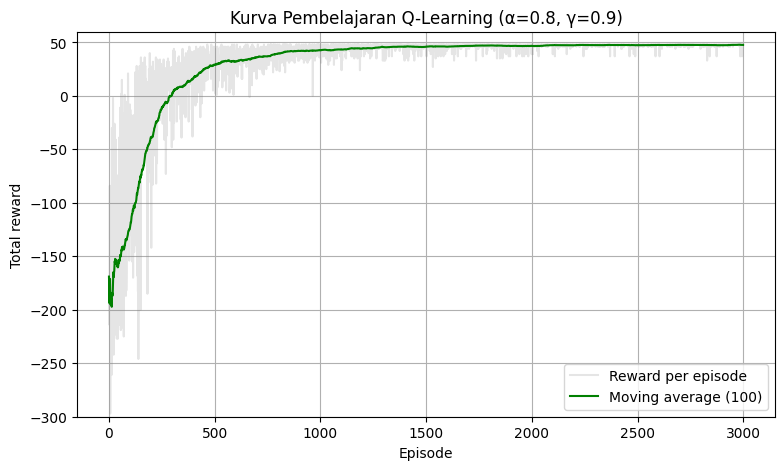

In [ ]:
Q, R, E = train()
tot, steps, ok, path = greedy_eval(Q)
print("Greedy: total reward", tot, "| langkah", steps, "| sukses", ok)
print("Rute:", path)
print("MA100 awal:", R[:100].mean(), "| MA100 akhir:", R[-100:].mean())
print("MA100 pertama kali > 0 pada episode:", int(np.argmax(ma(R) > 0)))

plt.figure(figsize=(9, 5))
plt.plot(R, alpha=.2, color="gray", label="Reward per episode")
plt.plot(ma(R), color="green", label="Moving average (100)")
plt.title("Kurva Pembelajaran Q-Learning (α=0.8, γ=0.9)")
plt.xlabel("Episode"); plt.ylabel("Total reward"); plt.legend(); plt.grid(True); plt.ylim(-300, 60)
plt.show()

## 4. Kebijakan Optimal (Policy)

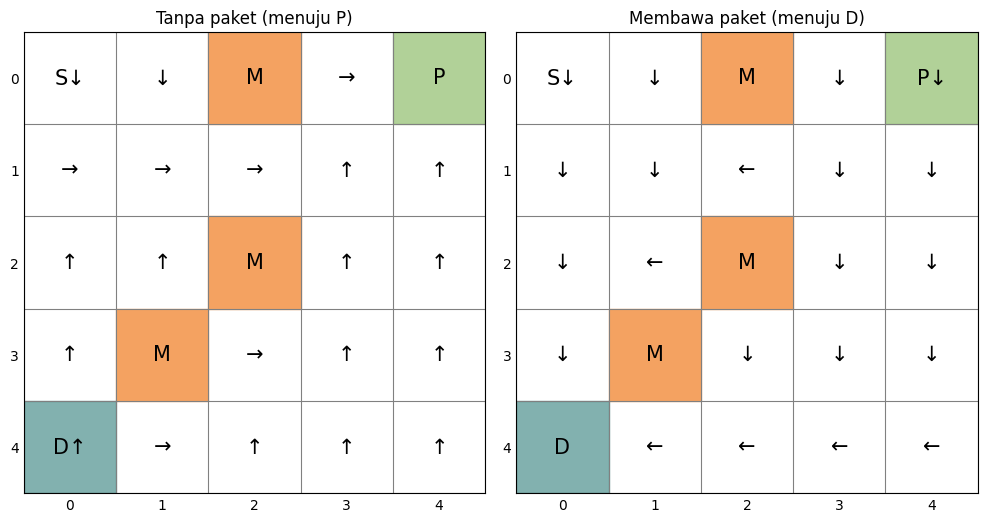

[[ 8.57 11.75  8.57 11.75]
 [28.37 33.74 28.37 25.43]
 [10.75 14.16  9.57 10.83]
 [24.43 29.37 29.37 12.89]
 [18.83 16.85 11.75 23.15]
 [20.89 25.43 25.43 18.7 ]
 [22.15 19.83 10.83 26.83]
 [17.7  21.89 12.89 15.83]
 [ 0.    0.    0.    0.  ]
 [14.83 18.7  18.7  14.83]]


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
plot_policy(Q, ax); plt.tight_layout(); plt.show()
print(np.round(Q[:10], 2))

## 5. Eksperimen Hiperparameter: discount factor γ
Bandingkan γ=0.9 (default) dengan γ=0.0 (ekstrem rendah). γ=0.1 ditambahkan sebagai pembanding.

γ=0.0 greedy: (-100, 100, False) | MA100 akhir: -100.35
γ=0.1 greedy: (48, 14, True) | MA100 akhir: 47.66


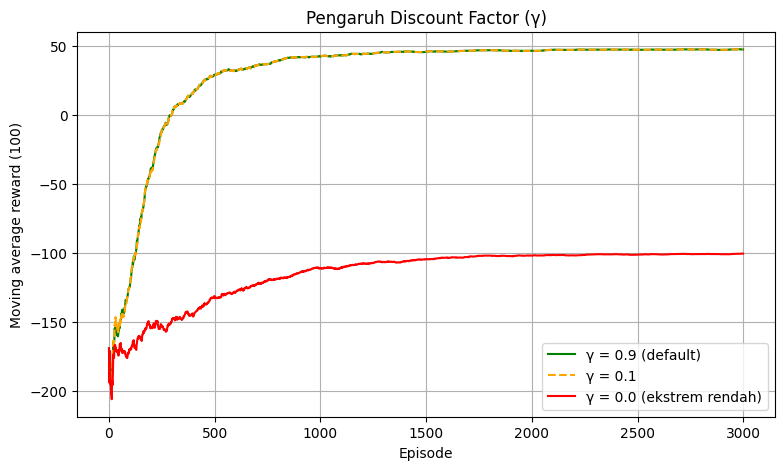

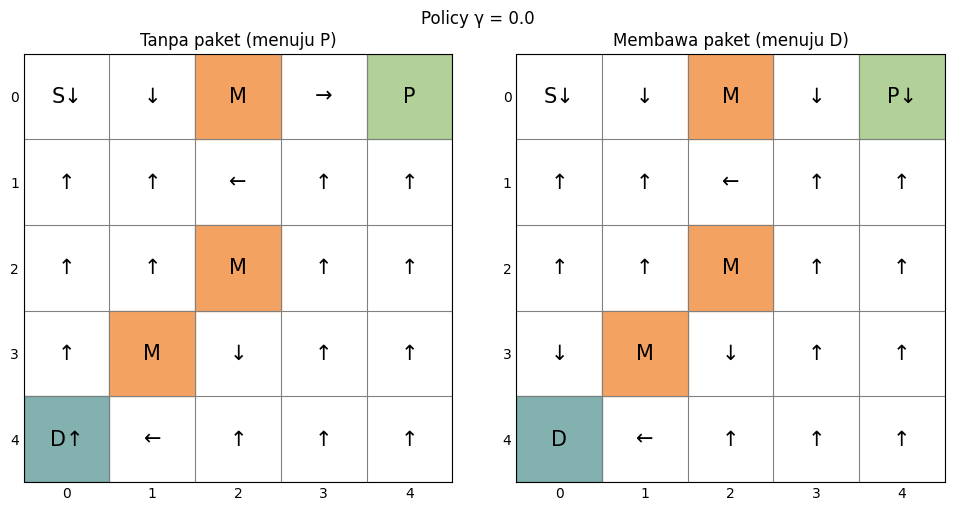

In [ ]:
Q2, R2, _ = train(gamma=0.0)
Q3, R3, _ = train(gamma=0.1)
print("γ=0.0 greedy:", greedy_eval(Q2)[:3], "| MA100 akhir:", R2[-100:].mean())
print("γ=0.1 greedy:", greedy_eval(Q3)[:3], "| MA100 akhir:", R3[-100:].mean())

plt.figure(figsize=(9, 5))
plt.plot(ma(R), color="green", label="γ = 0.9 (default)")
plt.plot(ma(R3), color="orange", ls="--", label="γ = 0.1")
plt.plot(ma(R2), color="red", label="γ = 0.0 (ekstrem rendah)")
plt.title("Pengaruh Discount Factor (γ)"); plt.xlabel("Episode"); plt.ylabel("Moving average reward (100)")
plt.legend(); plt.grid(True); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 5)); plot_policy(Q2, ax); plt.suptitle("Policy γ = 0.0"); plt.tight_layout(); plt.show()